# 02. Core Visualizations with Matplotlib
**Objective:** Build fundamental business charts (bar, line) using pure Matplotlib. Ensure clean, professional aesthetics.


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Ensure output directory exists for exported charts
os.makedirs('../visualizations/charts', exist_ok=True)

# Load PROCESSED data
df = pd.read_csv('../data/processed/cleaned_ecommerce_sales.csv')

# Global Matplotlib Settings for a subtle, cool aesthetic
plt.rcParams.update({
    'axes.facecolor': '#f8f9fa', 
    'grid.color': '#e9ecef', 
    'grid.linestyle': '--',
    'axes.edgecolor': '#cccccc'
})


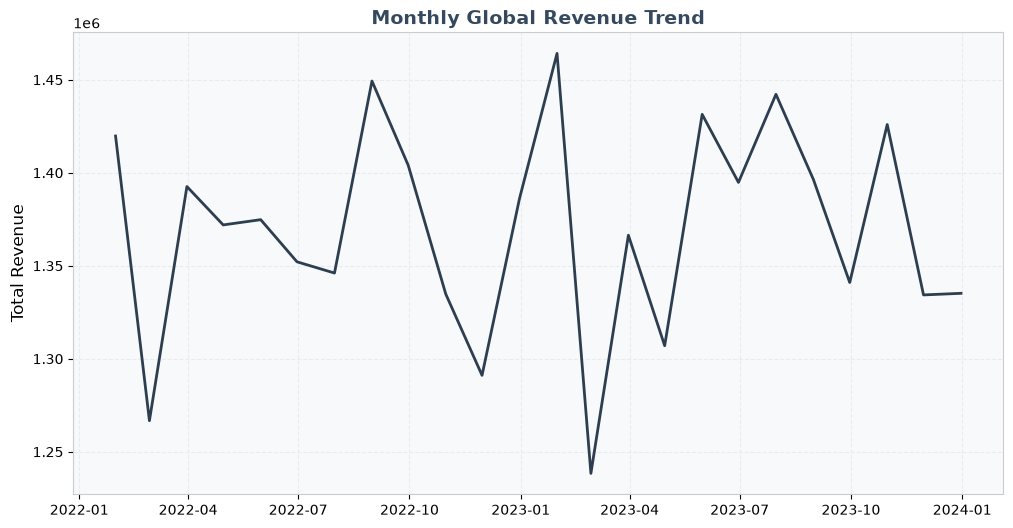

In [11]:
# 1. Revenue Trend Over Time (Line Chart)
if 'order_date' in df.columns and 'total_revenue' in df.columns:
    df['order_date'] = pd.to_datetime(df['order_date'])
    monthly_revenue = df.set_index('order_date').resample('ME')['total_revenue'].sum()
    
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(monthly_revenue.index, monthly_revenue.values, color='#2c3e50', linewidth=2)
    
    ax.set_title('Monthly Global Revenue Trend', fontsize=14, fontweight='bold', color='#34495e')
    ax.set_ylabel('Total Revenue', fontsize=12)
    ax.grid(True)
    
    plt.savefig('../visualizations/charts/monthly_revenue_trend.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print('ERROR: Missing \'order_date\' or \'total_revenue\' column. Check df.columns!')
